# Project1 CS-433

**Notes on implementation from project1_description.pdf :**

For SGD, you must use the standard mini-batch-size 1 (sample just one datapoint).
The mean squared error formula has a factor 0.5 to be consistent with the lecture notes. For least squares, you are allowed to use everything from numpy.linalg but not numpy.linalg.lstsq. All vectors should be implemented as 1D arrays with shape (X,) instead of (X, 1).


Return type: Note that all functions should return: (w, loss), which is the last weight vector of the
method, and the corresponding loss value (cost function). Note that while in previous labs you might
have kept track of all encountered w for iterative methods, here we only want the last one. Moreover, the
loss returned by the regularized methods (ridge regression and reg logistic regression) should
not include the penalty term.



## Imports and Loading Data

In [14]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from helpers import load_csv_data, create_csv_submission
from implementations import (
    compute_mse_loss,
    negative_log_likelihood,
    mean_squared_error_gd,
    mean_squared_error_sgd,
    logistic_regression,
    reg_logistic_regression,
    least_squares,
    ridge_regression,
)

%load_ext autoreload
%autoreload 2

sns.set_theme()

# one seed for everything random: the data split and the SGD samples
# (implementations.py draws from numpy's global RNG, so np.random.seed covers it)
SEED = 42
np.random.seed(SEED)

data_path = "data/"
# since the dataset is large (328k rows) we subsample first (every 50th row)
# then train on whole dataset once the implementation is validated i.e. set sub_sample = False
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_path, sub_sample=False)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
print(x_train.shape)
print(x_test.shape)

(328135, 321)
(109379, 321)


## Preprocessing Data

**for logistic regression:**
- Labels: the logistic regression functions expect y in {0, 1}, but load_csv_data gives y in {−1, 1}. Convert first with y01 = (y_train + 1) / 2. Convert back to −1/1 for predictions for the submission. (We don't implement the loss for y in {−1, 1} because then we would fail the tests provided by the course.)
- Feature scaling: some columns hold huge values, for example SEQNO is around 2,015,015,629. Then tx @ w gets very large and np.exp in sigmoid overflows. You'll see RuntimeWarning: overflow and training will behave badly. Standardize the features and handle the NaNs before training. The loss itself is already safe from this because of logaddexp.

**Split:** the labelled data (x_train, y_train) is split 80/10/10 into train / validation / test.
- train: fit the weights and the standardization statistics (mean, std), so no information leaks from the other splits
- validation: pick the hyperparameters (gamma, lambda_) in the sweeps
- test: used only once, in the final comparison, to report train vs. test results

x_test from load_csv_data has no labels, it is only used for the submission (renamed tx_sub after preprocessing).

In [16]:
import warnings

# --- 80/10/10 split of the labelled data into train / validation / test ---
N = len(y_train)
perm = np.random.default_rng(SEED).permutation(N)
n_tr, n_va = int(0.8 * N), int(0.1 * N)
idx_tr, idx_va, idx_te = perm[:n_tr], perm[n_tr : n_tr + n_va], perm[n_tr + n_va :]

# --- standardization statistics from the train split only ---
# columns that are entirely NaN in the train split give nan (numpy warns about it, silenced here)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    mean = np.nanmean(x_train[idx_tr], axis=0)
    std = np.nanstd(x_train[idx_tr], axis=0)
keep = std > 0  # drop constant columns (std = 0, would divide by zero) and all-NaN columns (std = nan)


def preprocess(x):
    """Standardize with the train statistics, replace NaN by 0 (= the train mean
    after standardizing) and add a bias column of ones as first column."""
    x = (x[:, keep] - mean[keep]) / std[keep]
    x = np.nan_to_num(x, nan=0.0)
    return np.c_[np.ones(len(x)), x]


tx_tr, tx_va, tx_te = (preprocess(x_train[idx]) for idx in (idx_tr, idx_va, idx_te))
y_tr, y_va, y_te = y_train[idx_tr], y_train[idx_va], y_train[idx_te]
tx_sub = preprocess(x_test)  # unlabelled, only for the submission

# labels in {0, 1} for the logistic regression functions
y_tr01, y_va01, y_te01 = ((y + 1) / 2 for y in (y_tr, y_va, y_te))

print(f"dropped {np.sum(~keep)} constant / all-NaN columns -> {tx_tr.shape[1]} features (incl. bias)")
print(f"train {tx_tr.shape}  validation {tx_va.shape}  test {tx_te.shape}  submission {tx_sub.shape}")
print(f"positive rate: train {np.mean(y_tr == 1):.3f}  validation {np.mean(y_va == 1):.3f}  test {np.mean(y_te == 1):.3f}")

dropped 6 constant / all-NaN columns -> 316 features (incl. bias)
train (262508, 316)  validation (32813, 316)  test (32814, 316)  submission (109379, 316)
positive rate: train 0.088  validation 0.088  test 0.089


## Training helpers

The functions in implementations.py only return the final (w, loss). To get the training loss after every epoch without redoing gradient steps, we call them in chunks and warm-start each chunk from the previous w (initial_w = last w). Each update only depends on the current w, so e.g. 10 + 10 iterations give exactly the same w as 20 iterations (for SGD as well, since the RNG is seeded once per run and continues where it left off). The loss returned by each chunk is the training loss at that w.

- GD / logistic regression: 1 epoch = 1 iteration (one full-gradient step over the train set)
- SGD: 1 epoch = N_train iterations (single-sample steps, one pass worth of samples)

Hyperparameters are chosen by sweeps: for each value we train with checkpoints and keep the value with the lowest **validation** loss at the last epoch. The number of epochs is not swept: the training curve shows where it flattens.

In [17]:
def run_with_checkpoints(step, w0, n_epochs, iters_per_epoch=1, seed=SEED):
    """Train in chunks of iters_per_epoch steps, warm-starting each chunk from the last w.

    Args:
        step (callable): step(w, k) -> (w, loss), a function of implementations.py
            with everything fixed except initial_w and max_iters
        w0 (np.ndarray): initial weight vector, shape (D,)
        n_epochs (int): number of chunks
        iters_per_epoch (int): max_iters passed to step for each chunk
        seed (int): seed for the global RNG (used by SGD)

    Returns:
        tuple: (ws, losses) with ws shape (n_epochs + 1, D) the weights after each epoch
            and losses shape (n_epochs + 1,) the training losses (index 0 = at w0)
    """
    np.random.seed(seed)
    w, loss = step(w0, 0)  # 0 iterations: loss at w0
    ws, losses = [w], [loss]
    for _ in range(n_epochs):
        w, loss = step(w, iters_per_epoch)
        ws.append(w)
        losses.append(loss)
        if not np.isfinite(loss):  # diverged, no point in continuing
            break
    return np.array(ws), np.array(losses)


def sweep(make_step, values, w0, n_epochs, iters_per_epoch, val_loss):
    """Train once per hyperparameter value and select the value with the lowest validation loss.

    Args:
        make_step (callable): make_step(value) -> step(w, k), see run_with_checkpoints
        values (list): hyperparameter values to try
        w0, n_epochs, iters_per_epoch: see run_with_checkpoints
        val_loss (callable): val_loss(w) -> validation loss of the final weights

    Returns:
        tuple: (results, best) with results[value] = dict(ws, losses, val_loss)
            and best the value with the lowest finite validation loss
    """
    results = {}
    for v in values:
        # diverging runs overflow on purpose, we detect them through the loss instead
        with np.errstate(over="ignore", invalid="ignore"):
            ws, losses = run_with_checkpoints(make_step(v), w0, n_epochs, iters_per_epoch)
            vl = val_loss(ws[-1])
        results[v] = dict(ws=ws, losses=losses, val_loss=vl)
        print(f"  {v:<8g} train loss {losses[-1]:<12.5g} validation loss {vl:.5g}")
    best = min((v for v in values if np.isfinite(results[v]["val_loss"])),
               key=lambda v: results[v]["val_loss"])
    print(f"best: {best:g}")
    return results, best


def plot_sweep(results, best, title, param="gamma", epoch_label="epoch"):
    """Training loss vs. epoch, one line per hyperparameter value (log scale).
    Runs whose loss ends above its starting value are labelled as diverged."""
    fig, ax = plt.subplots(figsize=(8, 4.5))
    colors = sns.color_palette("viridis", len(results))
    for c, (v, r) in zip(colors, results.items()):
        losses = r["losses"]
        finite = np.isfinite(losses)
        diverged = not finite.all() or losses[finite][-1] > losses[0]
        label = f"{param} = {v:g}" + (" (best)" if v == best else "") + (" (diverged)" if diverged else "")
        ax.plot(np.flatnonzero(finite), losses[finite], color=c,
                lw=3 if v == best else 1.5, ls="--" if diverged else "-", label=label)
    ax.set_yscale("log")
    ax.set_ylim(top=2 * results[best]["losses"][0])  # keep diverging runs from squashing the plot
    ax.set(title=title, xlabel=epoch_label, ylabel="training loss")
    ax.legend(fontsize=9)
    plt.show()


def predict(tx, w, threshold=0.0):
    """Labels in {-1, 1}: +1 if x^T w >= threshold. The default 0 is the sign of x^T w
    (for logistic regression the same as sigma(x^T w) >= 0.5)."""
    return np.where(tx @ w >= threshold, 1, -1)


def accuracy(y, y_pred):
    return np.mean(y == y_pred)


def f1_score(y, y_pred):
    """F1 of the positive class (+1). F1 = 2 TP / (2 TP + FP + FN)"""
    tp = np.sum((y_pred == 1) & (y == 1))
    fp = np.sum((y_pred == 1) & (y == -1))
    fn = np.sum((y_pred == -1) & (y == 1))
    return 2 * tp / (2 * tp + fp + fn) if tp > 0 else 0.0


def tune_threshold(tx, y, w, n_candidates=200):
    """Pick the cutoff on x^T w that maximizes F1 on (tx, y). Call it on the validation set.

    With only ~8.5% positives the default cutoff 0 predicts far too few positives.
    The candidates are quantiles of the scores x^T w, so the grid adapts to the scale
    of each model (MSE scores lie around [-1, 1], logistic scores are log-odds).

    Returns:
        tuple: (threshold, F1 at that threshold)
    """
    scores = tx @ w
    candidates = np.unique(np.quantile(scores, np.linspace(0, 1, n_candidates)))
    f1s = [f1_score(y, np.where(scores >= t, 1, -1)) for t in candidates]
    best = int(np.argmax(f1s))
    return candidates[best], f1s[best]


w0 = np.zeros(tx_tr.shape[1])

## Mean Squared Error GD

  0.001    train loss 0.37024      validation loss 0.37
  0.003    train loss 0.24151      validation loss 0.24142
  0.01     train loss 0.14412      validation loss 0.14414
  0.03     train loss 0.1375       validation loss 0.1376
  0.1      train loss 0.45443      validation loss 0.46068
best: 0.03


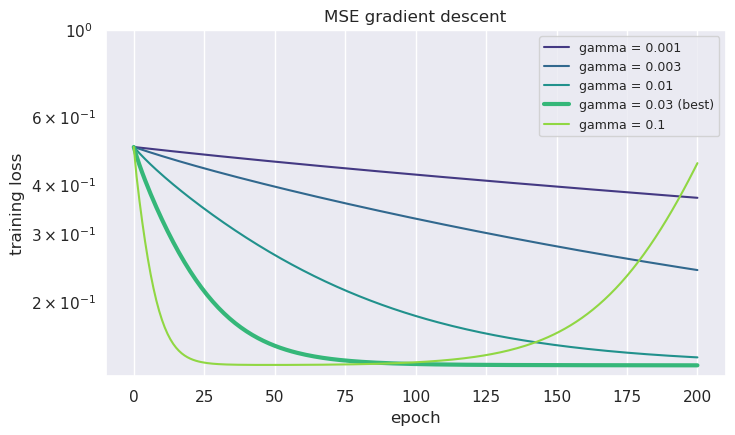

In [18]:
gd_gammas = [0.001, 0.003, 0.01, 0.03, 0.1]
gd_epochs = 200

gd_results, gd_gamma = sweep(
    lambda g: lambda w, k: mean_squared_error_gd(y_tr, tx_tr, w, k, g),
    gd_gammas, w0, gd_epochs, iters_per_epoch=1,
    val_loss=lambda w: compute_mse_loss(y_va, tx_va, w),
)
plot_sweep(gd_results, gd_gamma, "MSE gradient descent")

## Mean Squared Error SGD

  0.0001   train loss 0.13958      validation loss 0.14012
  0.0003   train loss 1.0392e+139  validation loss 1.3209e+139
  0.001    train loss inf          validation loss inf
  0.003    train loss inf          validation loss inf
best: 0.0001


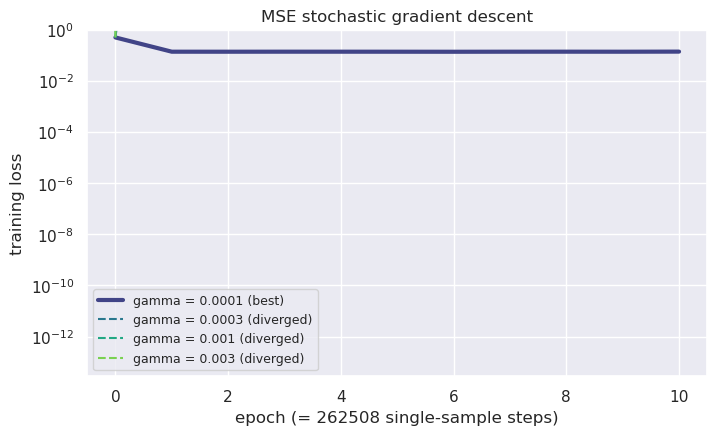

In [19]:
sgd_gammas = [1e-4, 3e-4, 1e-3, 3e-3]
sgd_epochs = 10

sgd_results, sgd_gamma = sweep(
    lambda g: lambda w, k: mean_squared_error_sgd(y_tr, tx_tr, w, k, g),
    sgd_gammas, w0, sgd_epochs, iters_per_epoch=len(y_tr),
    val_loss=lambda w: compute_mse_loss(y_va, tx_va, w),
)
plot_sweep(sgd_results, sgd_gamma, "MSE stochastic gradient descent",
           epoch_label=f"epoch (= {len(y_tr)} single-sample steps)")

## Least Squares

Closed-form solution of the normal equations X^T X w = X^T y: a single linear solve, so there is no gamma and no epochs.

If X^T X is singular (linearly dependent columns, e.g. duplicated features) the solution is not unique and np.linalg.solve returns numerically meaningless weights, even though the training loss looks good. The cell prints the rank of tx_tr and the condition number of X^T X to check this.

In [20]:
w_ls, loss_ls = least_squares(y_tr, tx_tr)
val_loss_ls = compute_mse_loss(y_va, tx_va, w_ls)

print(f"rank of tx_tr: {np.linalg.matrix_rank(tx_tr)} of {tx_tr.shape[1]} columns, "
      f"cond(X^T X) = {np.linalg.cond(tx_tr.T @ tx_tr):.3g}")
print(f"train loss {loss_ls:.5g}  validation loss {val_loss_ls:.5g}  max |w| {np.abs(w_ls).max():.3g}")

rank of tx_tr: 310 of 316 columns, cond(X^T X) = 9.31e+18
train loss 0.13635  validation loss 0.13672  max |w| 2.79


## Ridge Regression

Closed form (X^T X + 2N lambda I) w = X^T y. For any lambda_ > 0 the matrix is invertible, which fixes the singular X^T X of least squares.

We sweep lambda_ on a log grid and keep the value with the lowest validation MSE. There are no epochs, so instead of loss curves we plot the train and validation loss against lambda_: small lambda_ fits the training set best (overfitting, validation loss goes up), large lambda_ shrinks w towards 0 (underfitting, both go up).

  1e-08    train loss 0.13635    validation loss 0.13672
  3e-08    train loss 0.13635    validation loss 0.13672
  1e-07    train loss 0.13635    validation loss 0.13672
  3e-07    train loss 0.13635    validation loss 0.13672
  1e-06    train loss 0.13635    validation loss 0.13672
  3e-06    train loss 0.13636    validation loss 0.13671
  1e-05    train loss 0.13638    validation loss 0.13672
  3e-05    train loss 0.13648    validation loss 0.13678
  1e-04    train loss 0.13665    validation loss 0.13692
  3e-04    train loss 0.13679    validation loss 0.13704
  1e-03    train loss 0.13687    validation loss 0.13710
  3e-03    train loss 0.13694    validation loss 0.13715
  1e-02    train loss 0.13717    validation loss 0.13734
  3e-02    train loss 0.13851    validation loss 0.13862
  1e-01    train loss 0.14724    validation loss 0.14728
  3e-01    train loss 0.18977    validation loss 0.18975
  1e+00    train loss 0.29205    validation loss 0.29194
best: 3e-06


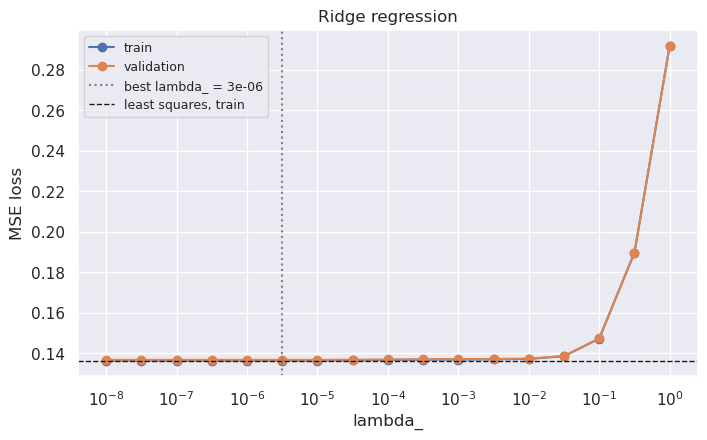

In [21]:
ridge_lambdas = np.logspace(-8, 0, 17)

ridge_results = {}
for lam in ridge_lambdas:
    w, loss = ridge_regression(y_tr, tx_tr, lam)
    ridge_results[lam] = dict(w=w, train_loss=loss, val_loss=compute_mse_loss(y_va, tx_va, w))
    print(f"  {lam:<8.0e} train loss {loss:<10.5f} validation loss {ridge_results[lam]['val_loss']:.5f}")
ridge_lambda = min(ridge_lambdas, key=lambda lam: ridge_results[lam]["val_loss"])
print(f"best: {ridge_lambda:.0e}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ridge_lambdas, [ridge_results[lam]["train_loss"] for lam in ridge_lambdas], "o-", label="train")
ax.plot(ridge_lambdas, [ridge_results[lam]["val_loss"] for lam in ridge_lambdas], "o-", label="validation")
ax.axvline(ridge_lambda, color="gray", ls=":", label=f"best lambda_ = {ridge_lambda:.0e}")
ax.axhline(loss_ls, color="k", ls="--", lw=1, label="least squares, train")
ax.set(xscale="log", title="Ridge regression", xlabel="lambda_", ylabel="MSE loss")
ax.legend(fontsize=9)
plt.show()

## Logistic Regression 

  0.01     train loss 0.45332      validation loss 0.45316
  0.03     train loss 0.31377      validation loss 0.31373
  0.1      train loss 0.24274      validation loss 0.24278
  0.3      train loss 0.22811      validation loss 0.2283
  1        train loss 0.22553      validation loss 0.22577
best: 1


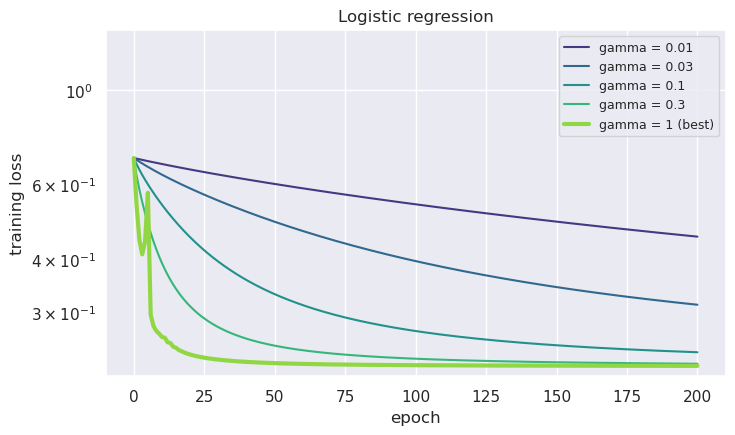

In [22]:
lr_gammas = [0.01, 0.03, 0.1, 0.3, 1.0]
lr_epochs = 200

lr_results, lr_gamma = sweep(
    lambda g: lambda w, k: logistic_regression(y_tr01, tx_tr, w, k, g),
    lr_gammas, w0, lr_epochs, iters_per_epoch=1,
    val_loss=lambda w: negative_log_likelihood(y_va01, tx_va, w),
)
plot_sweep(lr_results, lr_gamma, "Logistic regression")

## Regularized Logistic Regression

We keep the best gamma of logistic regression and sweep lambda_. lambda_ is chosen on the validation loss: the training loss can't be used, since the penalty always makes it larger.

  1e-05    train loss 0.22554      validation loss 0.22578
  0.0001   train loss 0.22558      validation loss 0.22582
  0.001    train loss 0.22662      validation loss 0.22685
  0.01     train loss 0.24759      validation loss 0.24765
  0.1      train loss 0.42852      validation loss 0.43029
best: 1e-05


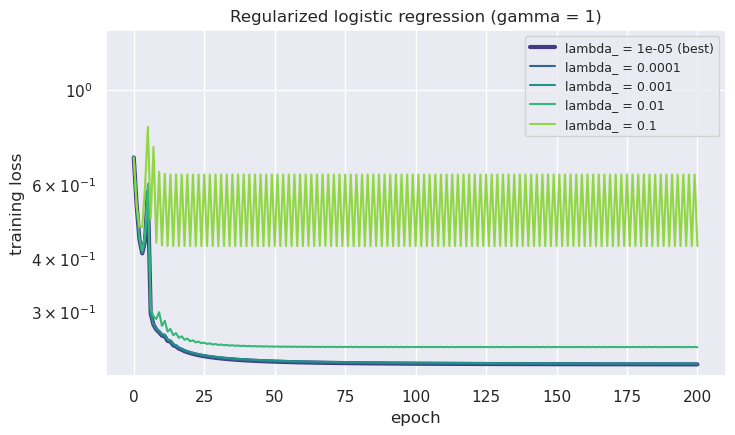

In [23]:
reg_lambdas = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
reg_epochs = lr_epochs

reg_results, reg_lambda = sweep(
    lambda lam: lambda w, k: reg_logistic_regression(y_tr01, tx_tr, lam, w, k, lr_gamma),
    reg_lambdas, w0, reg_epochs, iters_per_epoch=1,
    val_loss=lambda w: negative_log_likelihood(y_va01, tx_va, w),
)
plot_sweep(reg_results, reg_lambda, f"Regularized logistic regression (gamma = {lr_gamma:g})",
           param="lambda_")

## Comparison: train vs. test

Best hyperparameters of each method (chosen on the validation set), evaluated on the train and test splits. Loss is MSE for the MSE methods (GD, SGD, least squares, ridge) and the negative log-likelihood for the logistic ones, so losses can only be compared within a family. Accuracy and F1 are comparable across all methods. F1 matters more than accuracy here: only about 8.5% of the labels are positive, so always predicting -1 already gives about 91% accuracy (and F1 = 0).

- **Training curves:** only for the iterative methods. On the MSE GD / SGD plots the least squares training loss is drawn as the lower bound they converge to.
- **Cutoff:** a datapoint is predicted +1 if x^T w >= cutoff. For each method the cutoff is tuned on the validation set to maximize F1 (tune_threshold). The table shows F1 at the default cutoff 0 next to F1 at the tuned cutoff. Accuracy is at the tuned cutoff, so it drops a bit: we trade some false positives for many more true positives.
- **Best method:** picked by **validation** F1 at the tuned cutoff. That number is slightly optimistic, since the cutoff was tuned on the same split. The test split is only used to report how the choice does on unseen data.

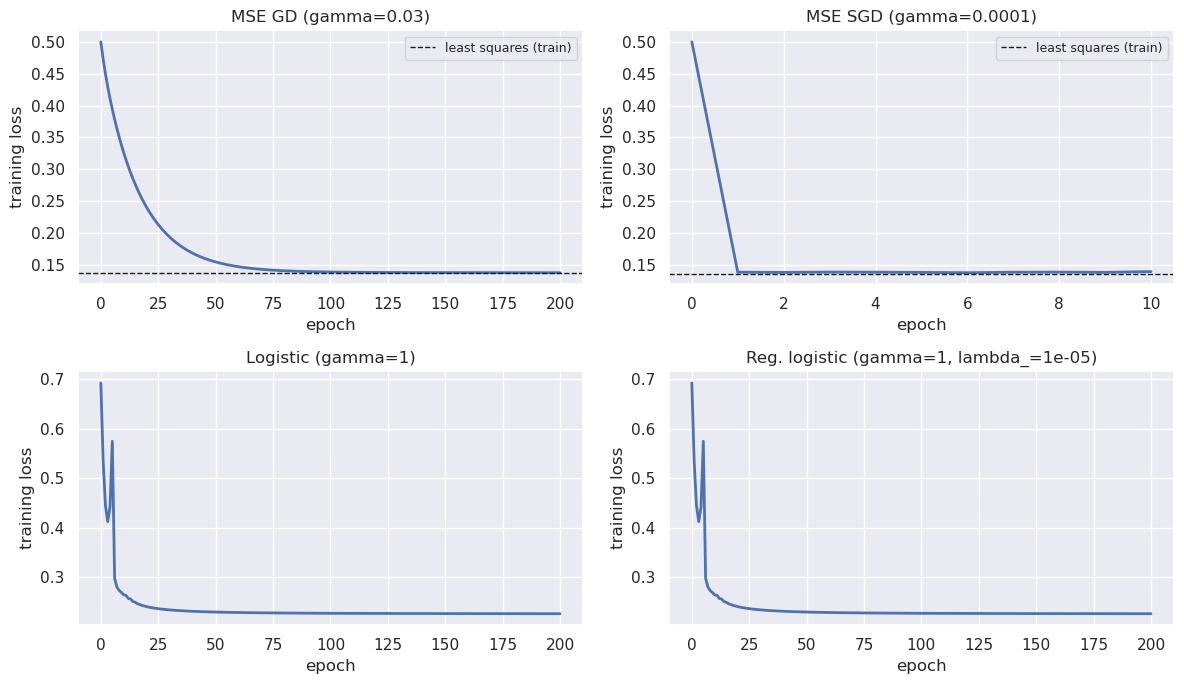

method         params                      cutoff  split         loss  accuracy  F1 (0)      F1
MSE GD         gamma=0.03                  -0.578  train       0.1375     0.862   0.004   0.407
MSE GD         gamma=0.03                  -0.578  test         0.139     0.860   0.004   0.400
MSE SGD        gamma=0.0001                -0.570  train       0.1396     0.868   0.007   0.392
MSE SGD        gamma=0.0001                -0.570  test        0.1414     0.865   0.007   0.386
Least squares  closed form                 -0.565  train       0.1364     0.866   0.014   0.413
Least squares  closed form                 -0.565  test        0.1379     0.864   0.017   0.411
Ridge          lambda_=3e-06               -0.572  train       0.1364     0.863   0.013   0.413
Ridge          lambda_=3e-06               -0.572  test        0.1379     0.862   0.016   0.412
Logistic       gamma=1                     -1.478  train       0.2255     0.859   0.181   0.416
Logistic       gamma=1                  

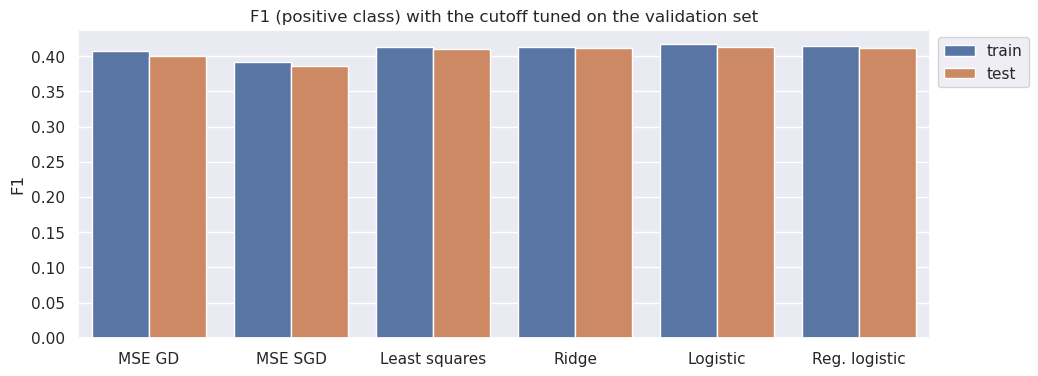

In [24]:
models = {
    # name: final weights, hyperparameters, loss function, labels for the loss (train, validation, test), training curve
    "MSE GD": dict(w=gd_results[gd_gamma]["ws"][-1], params=f"gamma={gd_gamma:g}", loss_fn=compute_mse_loss,
                   y_loss=(y_tr, y_va, y_te), curve=gd_results[gd_gamma]["losses"]),
    "MSE SGD": dict(w=sgd_results[sgd_gamma]["ws"][-1], params=f"gamma={sgd_gamma:g}", loss_fn=compute_mse_loss,
                    y_loss=(y_tr, y_va, y_te), curve=sgd_results[sgd_gamma]["losses"]),
    "Least squares": dict(w=w_ls, params="closed form", loss_fn=compute_mse_loss,
                          y_loss=(y_tr, y_va, y_te), curve=None),
    "Ridge": dict(w=ridge_results[ridge_lambda]["w"], params=f"lambda_={ridge_lambda:.0e}", loss_fn=compute_mse_loss,
                  y_loss=(y_tr, y_va, y_te), curve=None),
    "Logistic": dict(w=lr_results[lr_gamma]["ws"][-1], params=f"gamma={lr_gamma:g}", loss_fn=negative_log_likelihood,
                     y_loss=(y_tr01, y_va01, y_te01), curve=lr_results[lr_gamma]["losses"]),
    "Reg. logistic": dict(w=reg_results[reg_lambda]["ws"][-1], params=f"gamma={lr_gamma:g}, lambda_={reg_lambda:g}",
                          loss_fn=negative_log_likelihood, y_loss=(y_tr01, y_va01, y_te01),
                          curve=reg_results[reg_lambda]["losses"]),
}

# --- training loss curves of the best run of each iterative method ---
iterative = [name for name, m in models.items() if m["curve"] is not None]
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, name in zip(axes.flat, iterative):
    m = models[name]
    ax.plot(m["curve"], lw=2)
    if m["loss_fn"] is compute_mse_loss:
        ax.axhline(loss_ls, color="k", ls="--", lw=1, label="least squares (train)")
        ax.legend(fontsize=9)
    ax.set(title=f"{name} ({m['params']})", xlabel="epoch", ylabel="training loss")
fig.tight_layout()
plt.show()

# --- cutoff on x^T w per method, tuned on the validation set ---
for m in models.values():
    m["threshold"], _ = tune_threshold(tx_va, y_va, m["w"])

# --- train vs. test table (+ validation F1 used to pick the best method) ---
splits = [("train", tx_tr, y_tr), ("validation", tx_va, y_va), ("test", tx_te, y_te)]
rows = []
print(f"{'method':<15}{'params':<26}{'cutoff':>8}  {'split':<7}{'loss':>11}{'accuracy':>10}{'F1 (0)':>8}{'F1':>8}")
for name, m in models.items():
    for (split, tx, y_pm), y_loss in zip(splits, m["y_loss"]):
        y_pred = predict(tx, m["w"], m["threshold"])
        row = dict(name=name, split=split, loss=m["loss_fn"](y_loss, tx, m["w"]),
                   accuracy=accuracy(y_pm, y_pred), f1_0=f1_score(y_pm, predict(tx, m["w"])),
                   f1=f1_score(y_pm, y_pred))
        rows.append(row)
        if split != "validation":
            print(f"{name:<15}{m['params']:<26}{m['threshold']:>8.3f}  {split:<7}{row['loss']:>11.4g}"
                  f"{row['accuracy']:>10.3f}{row['f1_0']:>8.3f}{row['f1']:>8.3f}")

val_f1 = {r["name"]: r["f1"] for r in rows if r["split"] == "validation"}
test_f1 = {r["name"]: r["f1"] for r in rows if r["split"] == "test"}
best_name = max(val_f1, key=val_f1.get)
print(f"\nbest method on validation F1: {best_name} (cutoff {models[best_name]['threshold']:.3f}, "
      f"validation F1 {val_f1[best_name]:.3f}, test F1 {test_f1[best_name]:.3f})")

# --- train vs. test F1 at the tuned cutoff ---
shown = [r for r in rows if r["split"] != "validation"]
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(x=[r["name"] for r in shown], y=[r["f1"] for r in shown], hue=[r["split"] for r in shown], ax=ax)
ax.set(title="F1 (positive class) with the cutoff tuned on the validation set", ylabel="F1")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## Generating submission 

In [25]:
# predictions on the unlabelled set with the best method (validation F1) and its tuned cutoff, in {-1, 1}
m_sub = models[best_name]
y_pred_sub = predict(tx_sub, m_sub["w"], m_sub["threshold"])
print(f"{best_name} (cutoff {m_sub['threshold']:.3f}): "
      f"predicted positive rate on the submission set: {np.mean(y_pred_sub == 1):.3f}")

# uncomment to write the file
create_csv_submission(test_ids, y_pred_sub, "submission.csv")

Logistic (cutoff -1.478): predicted positive rate on the submission set: 0.153
